# Phase 8 — Weekly Mandi Price Forecasting

**What this notebook is.** An executable walkthrough of the completed Phase 8:
- the forecasting problem and the leakage-safe weekly dataset
- the baselines and models that were compared
- the frozen selection (D-42)
- the one-time 2021–2022 test
- the forecast output contract and error profile

**What it does not do.** It **reads** the saved Phase 8 artifacts. It does not retrain, re-select or re-test anything; the test runner itself refuses a second run (D-42). Raw rows are read only up to 2020-12-27, the end of validation.

## INDEX
1. Setup
2. The forecasting problem and time-based splits
3. From daily records to weekly examples (real data)
4. Features and leakage prevention
5. Baselines and models on validation (2019, 2020)
6. Uncertainty and the frozen selection (D-42)
7. The one-time 2021–2022 test, and why validation gains did not carry over
8. Forecast output contract and validation error profile
9. Summary

## 1. Setup

In [1]:
import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from Code.modelling import dataset as d
from Code.modelling import final_evaluation as fe
from Code.modelling import forecast_output as fo
from Code.modelling import arrivals as ar          # only for its CUTOFF constant (end of validation)

P8 = d.MODEL_DATA_DIR                              # Processed_Data/modelling/phase08 (frozen artifacts)
CUTOFF = ar.CUTOFF                                 # 2020-12-27: no raw row after this is read here
print("Interpreter:", sys.executable, "| Python", sys.version.split()[0])
print("Phase 8 artifacts:", P8)

Interpreter: C:\Python313\python.exe | Python 3.13.7
Phase 8 artifacts: Processed_Data\modelling\phase08


## 2. The forecasting problem and time-based splits

**Accepted decisions:**
- **D-38 — what is forecast:** the **weekly median usable modal price** (Rs/quintal, nominal) of each series (crop, state, district, market, variety), forecast **1, 2 and 4 weeks ahead** from the end of Sunday of week W. Weeks run Monday–Sunday.
- **D-39 — which records count:** only usable records count; `review`-flagged rows stay in, with a sensitivity check.
- **D-40 — time-based splits:** train 2002–2018; validation 2019 and 2020, reported separately; one-time test 2021–2022; 2023+ reserved. There is no random splitting anywhere.
- **D-41 — eligibility:** a series needs ≥ 365 usable price dates by the forecast date.

In [2]:
split = pd.read_csv(P8 / "split_definition.csv")
split

,period,first_target_sunday,last_target_sunday,weather_config,no_weather_config
0,train,2002-01-06,2018-12-30,True,True
1,val_2019,2019-01-06,2019-12-29,True,True
2,val_2020,2020-01-05,2020-12-27,True,True
3,test,2021-01-03,2022-12-25,True,True
4,holdout_no_weather,2023-01-01,last input date,False,True


## 3. From daily records to weekly examples (real data, ≤ 2020-12-27)

The builder (`Code/modelling/dataset.py`) turns each series' daily records into one row per forecast week:
- the **anchor row** is the last usable price of week W, and its Phase 6 features use only data from before it;
- the **target** is the median usable price of week W + h;
- a target week with no usable price produces **no example**; it is never filled in.

Here it is run on Onion only, using data up to the end of validation.

In [3]:
reg = d.registry_columns(pd.read_csv(d.REGISTRY_PATH))
onion = pd.read_parquet(d.FEATURE_DIR / "features_onion.parquet")
d.validate_schema(onion, reg, "Onion")
onion = onion[onion["reported_date"] <= CUTOFF]                    # never look past validation here
by_h, origins = d.build_examples(onion, reg)
for h, ex in by_h.items():
    d.validate_examples(ex, onion["reported_date"].max(), d.feature_columns(reg, "weather"))   # raises on any leak
counts = pd.DataFrame({h: ex["period"].value_counts() for h, ex in by_h.items()}).fillna(0).astype(int)
counts.columns = [f"h={h}" for h in counts.columns]
print("Examples per period (all leakage checks passed):")
counts

Examples per period (all leakage checks passed):


,h=1,h=2,h=4
period,,,
train,369902,359225,346880
val_2019,35321,34838,34300
val_2020,31183,29927,28082
outside,168,146,119


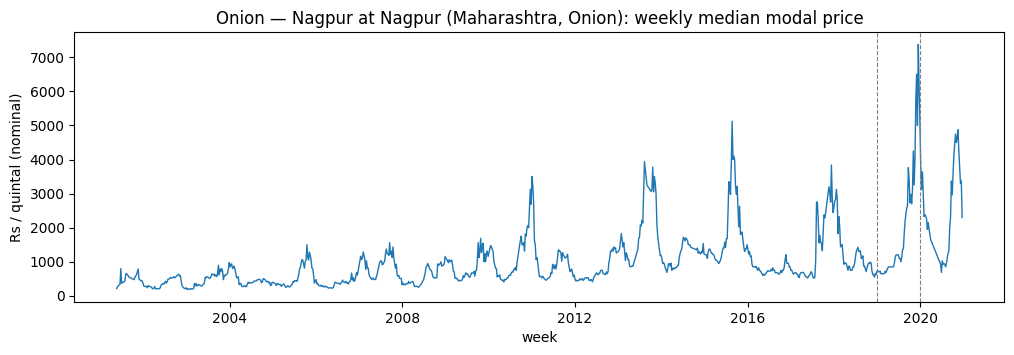

In [4]:
# One busy series as weekly medians: the forecast target is built from exactly these points
key = origins.groupby(d.SERIES, observed=True).size().idxmax()
s = origins.set_index(d.SERIES).loc[key].sort_values("week_start")
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(s["week_start"], s["origin_week_median"], lw=1)
ax.set_title(f"Onion — {key[3]} at {key[2]} ({key[1]}, {key[0]}): weekly median modal price")
ax.set_ylabel("Rs / quintal (nominal)"); ax.set_xlabel("week")
for y in ["2019-01-01", "2020-01-01"]:
    ax.axvline(pd.Timestamp(y), color="grey", ls="--", lw=0.8)
plt.show()

## 4. Features and leakage prevention

**Predictors** follow the feature registry roles:
- the Phase 6 history features of the anchor row (lags, rolling windows, arrivals, trailing weather, APY at lag 2);
- origin-week aggregates;
- target-week calendar fields.

Identifiers, targets and audit columns are rejected by `validate_examples`.

**Check below:** every value dated after a chosen forecast date is replaced with an absurd number, the weekly table is rebuilt, and none of the predictors at earlier forecast dates may change.

In [5]:
cols = [c for c in d.feature_columns(reg, "weather") if not c.startswith("tw_")]
keys = onion.groupby(d.SERIES, observed=True).size().nlargest(5).reset_index()[d.SERIES]   # 5 densest series
sub = onion.merge(keys, on=d.SERIES)
probe_origin = pd.Timestamp("2019-06-30")
late = sub["reported_date"] > probe_origin
print("rows after the probe date that get poisoned:", int(late.sum()))
poisoned = sub.copy()
poisoned[d.MODAL] = poisoned[d.MODAL].where(~late, 1e9)
for c in reg.loc[reg["role"] == "predictor", "column"]:
    if c in sub and pd.api.types.is_float_dtype(sub[c]):    # numeric history features; calendar fields are date-derived
        poisoned[c] = poisoned[c].where(~late, -1.0)
a = d.build_examples(sub, reg)[1]
b = d.build_examples(poisoned, reg)[1]
a, b = (x[x["origin_date"] <= probe_origin].reset_index(drop=True) for x in (a, b))
changed = int((a[cols].astype(str) != b[cols].astype(str)).to_numpy().sum())   # str: NaN == NaN, works for categoricals
print(f"{len(cols)} predictors x {len(a)} forecast weeks compared; values changed by future data: {changed}")
assert changed == 0

rows after the probe date that get poisoned: 1975


65 predictors x 3805 forecast weeks compared; values changed by future data: 0


## 5. Baselines and models on validation (2019 and 2020)

**Compared on identical rows:**
- **Persistence:** the last known weekly median, which is the benchmark.
- **Calendar climatology:** the only truly calendar-only forecast.
- **Calendar-adjusted persistence.**
- **Ridge** and **HistGradientBoosting**, plus one pre-specified **conservative HGB**.

**Metric:** MAPE (%) on the primary population.

In [6]:
mm = pd.concat([pd.read_csv(P8 / "model_validation_metrics.csv"),
                pd.read_csv(P8 / "hgb_conservative_validation_metrics.csv")])
mm = mm[(mm["experiment"] == "primary") & (mm["subset"] == "all") & (mm["period"] != "val_combined")]
mm["model"] = mm["model"] + np.where(mm["config"].isin(["weather", "no_weather"]), " (" + mm["config"] + ")", "")
pers = mm.drop_duplicates(["crop", "horizon_weeks", "period"]).assign(model="persistence", mape_pct=lambda x: x["persistence_mape_pct"])
show = pd.concat([pers, mm[mm["model"].isin(["ridge (weather)", "hgb (weather)", "hgb_conservative (weather)", "calendar_adjusted_persistence"])]])
table = show.pivot_table(index=["crop", "horizon_weeks", "model"], columns="period", values="mape_pct").round(2)
table

period                                              val_2019  val_2020
crop   horizon_weeks model                                            
Onion  1             calendar_adjusted_persistence      8.80     12.14
                     hgb (weather)                      8.75     13.57
                     hgb_conservative (weather)         8.45     10.79
                     persistence                        8.78     12.08
                     ridge (weather)                    8.73     10.76
       2             calendar_adjusted_persistence     12.98     19.13
                     hgb (weather)                     14.17     21.12
                     hgb_conservative (weather)        13.53     18.00
                     persistence                       12.89     19.70
                     ridge (weather)                   13.01     16.73
       4             calendar_adjusted_persistence     18.86     30.15
                     hgb (weather)                     20.17     34.37
                     hgb_conservative (weather)        19.21     30.93
                     persistence                       19.03     33.31
                     ridge (weather)                   18.39     25.08
Potato 1             calendar_adjusted_persistence      7.21      7.84
                     hgb (weather)                      7.30      8.19
                     hgb_conservative (weather)         7.10      7.68
                     persistence                        7.04      8.03
                     ridge (weather)                    7.60      7.83
       2             calendar_adjusted_persistence     10.53     11.97
                     hgb (weather)                     11.28     14.40
                     hgb_conservative (weather)        10.90     13.28
                     persistence                       10.02     12.60
                     ridge (weather)                   10.96     12.13
       4             calendar_adjusted_persistence     14.86     17.31
                     hgb (weather)                     16.45     21.55
                     hgb_conservative (weather)        15.62     20.36
                     persistence                       14.48     18.52
                     ridge (weather)                   15.42     18.17
Wheat  1             calendar_adjusted_persistence      1.78      2.33
                     hgb (weather)                      1.68      2.29
                     hgb_conservative (weather)         1.66      2.32
                     persistence                        1.79      2.32
                     ridge (weather)                    1.79      2.67
       2             calendar_adjusted_persistence      2.29      3.24
                     hgb (weather)                      2.17      3.40
                     hgb_conservative (weather)         2.14      3.34
                     persistence                        2.31      3.21
                     ridge (weather)                    2.27      3.70
       4             calendar_adjusted_persistence      3.06      4.56
                     hgb (weather)                      2.82      4.82
                     hgb_conservative (weather)         2.82      4.68
                     persistence                        3.13      4.52
                     ridge (weather)                    2.93      6.20

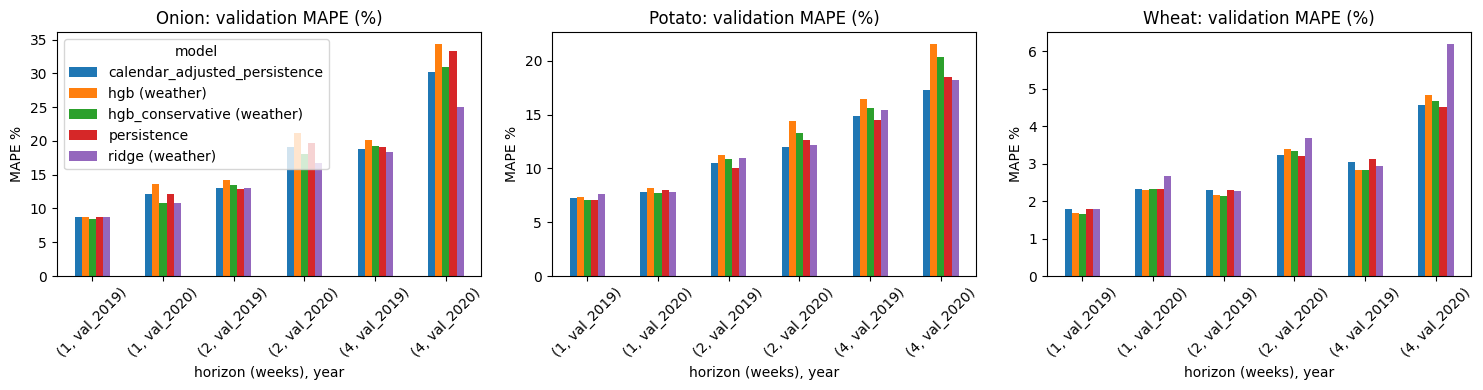

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, crop in zip(axes, ["Onion", "Potato", "Wheat"]):
    t = show[show["crop"] == crop].pivot_table(index=["horizon_weeks", "period"], columns="model", values="mape_pct")
    t.plot(kind="bar", ax=ax, rot=45, legend=(crop == "Onion"), title=f"{crop}: validation MAPE (%)")
    ax.set_xlabel("horizon (weeks), year"); ax.set_ylabel("MAPE %")
fig.tight_layout(); plt.show()

## 6. Uncertainty and the frozen selection (D-42)

**Paired series-level bootstrap.** Every candidate is compared with persistence on the same rows, with 95% intervals per year.

**Before the test, a candidate had to pass all four:**
1. intervals above 0 in both years, under series and market clustering;
2. the Bonferroni check;
3. at least a 2% gain in each year;
4. the same result without review-flagged targets.

**The two steps of selection:**
- The validation-stage proposal is shown first.
- **D-42** is the final, frozen choice: the project owner kept persistence for Onion at 4 weeks because the 2% rule was introduced after the Ridge results were seen. The freeze manifest is verified below.

In [8]:
prop = pd.read_csv(P8 / "selection_proposal.csv")[["crop", "horizon_weeks", "proposed", "candidates_passing_all"]]
fe.verify_freeze()                                          # raises if any frozen file changed
fz = pd.read_csv(fe.FREEZE)
final = {f"{c} h={h}": f"{m} ({cfg})" for (c, h), (m, cfg) in fe.SELECTED.items()}
prop["final_D42"] = [final.get(f"{c} h={h}", "persistence") for c, h in zip(prop["crop"], prop["horizon_weeks"])]
print("Freeze manifest verified:", fe.FREEZE)
prop

Freeze manifest verified: Processed_Data\modelling\phase08\test_freeze_manifest.csv


,crop,horizon_weeks,proposed,candidates_passing_all,final_D42
0,Onion,1,hgb_conservative (weather),1,hgb_conservative (weather)
1,Onion,2,persistence,0,persistence
2,Onion,4,ridge (weather),1,persistence
3,Potato,1,persistence,0,persistence
4,Potato,2,persistence,0,persistence
5,Potato,4,persistence,0,persistence
6,Wheat,1,persistence,0,persistence
7,Wheat,2,persistence,0,persistence
8,Wheat,4,persistence,0,persistence


## 7. The one-time 2021–2022 test, and why validation gains did not carry over

**How the test was run:** once, after the freeze, and never used for selection. Each approach is compared with persistence on identical rows. MAE is in Rs/quintal; positive improvement = better than persistence.

In [9]:
tr = pd.read_csv(P8 / "test_results.csv")
tb = pd.read_csv(P8 / "test_bootstrap.csv")
learned = tr[tr["approach"] != "persistence"][["crop", "horizon_weeks", "approach", "period", "n_obs", "mae", "persistence_mae",
                                               "rel_mae_improvement_pct", "rmse_improvement", "mape_improvement_pp"]]
ci = tb[tb["cluster"] == "series"].set_index("period")[["rel_mae_improvement_pct_ci_low", "rel_mae_improvement_pct_ci_high", "verdict"]]
learned.set_index("period").join(ci).round(2)

,crop,horizon_weeks,approach,n_obs,mae,persistence_mae,rel_mae_improvement_pct,rmse_improvement,mape_improvement_pp,rel_mae_improvement_pct_ci_low,rel_mae_improvement_pct_ci_high,verdict
period,,,,,,,,,,,,
test_2021,Onion,1,hgb_conservative,29879,239.05,227.31,-5.16,23.10,-0.42,-6.30,-4.05,worse
test_2022,Onion,1,hgb_conservative,34008,141.51,146.35,3.31,8.45,0.57,0.03,5.87,better
test_combined,Onion,1,hgb_conservative,63887,187.13,184.22,-1.58,16.16,0.11,-3.15,-0.18,worse


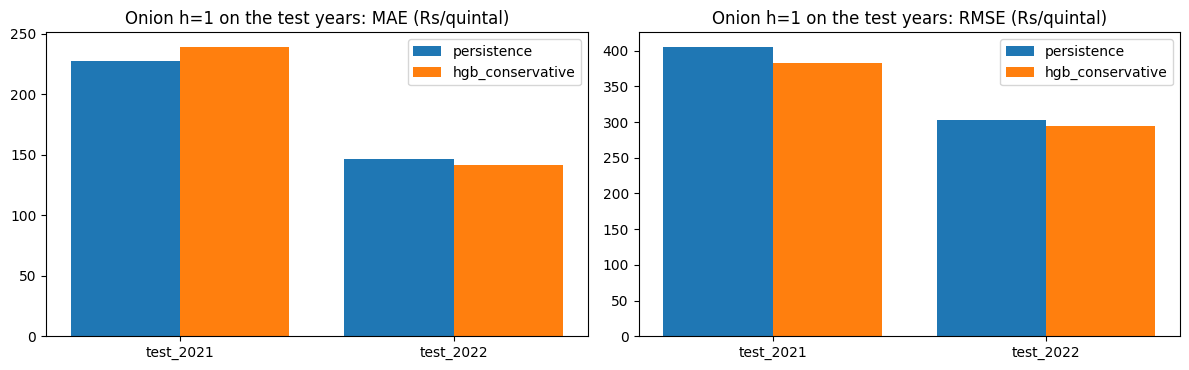

Validation skill vs persistence (MAE): {'val_2019': 0.055, 'val_2020': 0.137}
Test relative MAE improvement (%): {'test_2021': -5.16, 'test_2022': 3.31}


In [10]:
o1 = tr[(tr["crop"] == "Onion") & (tr["horizon_weeks"] == 1) & (tr["period"] != "test_combined")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(o1))
for ax, (m, p, lab) in zip(axes, [("mae", "persistence_mae", "MAE (Rs/quintal)"), ("rmse", "persistence_rmse", "RMSE (Rs/quintal)")]):
    ax.bar(x - 0.2, o1[p], 0.4, label="persistence"); ax.bar(x + 0.2, o1[m], 0.4, label="hgb_conservative")
    ax.set_xticks(x, o1["period"]); ax.set_title(f"Onion h=1 on the test years: {lab}"); ax.legend()
fig.tight_layout(); plt.show()
v = pd.read_csv(P8 / "hgb_conservative_validation_metrics.csv")
v = v[(v["crop"] == "Onion") & (v["horizon_weeks"] == 1) & (v["config"] == "weather") & (v["experiment"] == "primary")
      & (v["subset"] == "all") & (v["period"] != "val_combined")]
print("Validation skill vs persistence (MAE):", dict(zip(v["period"], v["skill_mae_vs_persistence"].round(3))))
print("Test relative MAE improvement (%):", dict(zip(o1["period"], o1["rel_mae_improvement_pct"].round(2))))

**Why the validation gain did not generalise.** The Onion one-week model:
- beat persistence in 2019 and 2020;
- was worse in 2021, borderline better in 2022, and **worse overall on MAE**;
- **improved RMSE in both test years**: it cuts a few large misses but adds many small errors.

**Reasons:**
- Two validation years are two market regimes, and 2020 included a price spike.
- The series-level intervals do not capture shocks shared across markets.

**What D-42 does now:** it is unchanged by the test. Persistence is the most reliable price forecast across 2019–2022.

## 8. Forecast output contract and validation error profile

`phase8-forecast-v1` is a **batch interface over historical data, not a live service**:
- **Persistence cells** are complete.
- **The Onion h = 1 learned cell** has no saved fitted model, so it returns an explicit `model_artifact_unavailable` with a null price. Nothing is invented.
- **Prediction intervals** are unavailable. The validation error profile gives **empirical error quantiles, not calibrated intervals**.

In [11]:
origin = pd.Timestamp("2020-12-20")                        # a Sunday inside validation
table_out = fo.forecast_table(origins.assign(crop="Onion"), "Onion", origin, onion["reported_date"].max())
print("Rows:", len(table_out), "| statuses:", table_out["prediction_status"].value_counts().to_dict())
table_out.groupby(["horizon_weeks", "approach", "prediction_status"]).size().rename("rows").to_frame()

Rows: 2166 | statuses: {'ok': 1444, 'model_artifact_unavailable': 722}


,,,rows
horizon_weeks,approach,prediction_status,
1,hgb_conservative,model_artifact_unavailable,722
2,persistence,ok,722
4,persistence,ok,722


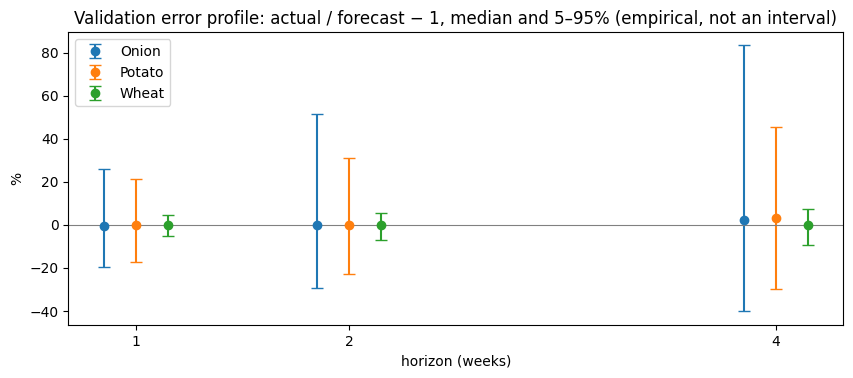

,crop,horizon_weeks,approach,n_obs,mae_rs_per_quintal,ratio_error_q05,ratio_error_q50,ratio_error_q95
2,Onion,1,hgb_conservative,55138,234.260,-0.197,-0.006,0.258
5,Onion,2,persistence,53747,405.131,-0.293,0.000,0.515
8,Onion,4,persistence,51754,627.948,-0.403,0.020,0.833
11,Potato,1,persistence,55600,112.438,-0.171,0.000,0.214
14,Potato,2,persistence,54607,165.592,-0.230,0.000,0.310
17,Potato,4,persistence,53368,235.329,-0.297,0.033,0.455
20,Wheat,1,persistence,57148,39.061,-0.053,0.000,0.045
23,Wheat,2,persistence,55868,51.979,-0.070,0.000,0.056
26,Wheat,4,persistence,54548,71.306,-0.094,0.000,0.074


In [12]:
prof = pd.read_csv(P8 / "forecast_error_profile.csv")
cm = prof[prof["period"] == "val_combined"]
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (crop, g) in enumerate(cm.groupby("crop")):
    ax.errorbar(g["horizon_weeks"] + (i - 1) * 0.15, 100 * g["ratio_error_q50"],
                yerr=[100 * (g["ratio_error_q50"] - g["ratio_error_q05"]), 100 * (g["ratio_error_q95"] - g["ratio_error_q50"])],
                fmt="o", capsize=4, label=crop)
ax.axhline(0, color="grey", lw=0.8); ax.set_xticks([1, 2, 4])
ax.set_title("Validation error profile: actual / forecast − 1, median and 5–95% (empirical, not an interval)")
ax.set_xlabel("horizon (weeks)"); ax.set_ylabel("%"); ax.legend(); plt.show()
cm[["crop", "horizon_weeks", "approach", "n_obs", "mae_rs_per_quintal", "ratio_error_q05", "ratio_error_q50", "ratio_error_q95"]].round(3)

## 9. Summary

**Done:**
- A leakage-safe weekly dataset, with its checks shown above.
- Baselines and models compared on identical rows, with 2019 and 2020 kept separate.
- A frozen selection (D-42) and a one-time test.
- A forecast output contract and an empirical error profile.

**The evidence:**
- **Persistence is the most reliable** weekly price forecast across 2019–2022.
- The one learned cell (Onion, 1 week) did not beat it on test MAE.

**Not done:**
- live forecasting;
- prediction intervals;
- a saved learned-model artifact;
- the 2023+ holdout, which stays reserved under `Phase_08_Modelling_Plan.md` §P.

Arrivals forecasting continues in `Phase_09_Arrivals_Model_Experiments.ipynb`.